In [29]:
import pandas as pd
import os
import glob
import pathlib
from matplotlib import pyplot as plt
import seaborn as sns
import copy
import numpy as np
import csv
import re
from matplotlib.patches import Patch

In [30]:
def _source_population_colors(source_data_dir, prip_data_dir, experiment_ids):
    """Return PriP-based minority/majority labels in residual order."""
    colors_by_timestep = []
    experiment_dirs = [
        os.path.join(source_data_dir, str(experiment_id))
        for experiment_id in experiment_ids
    ]
    for experiment_dir in experiment_dirs:
        experiment_id = os.path.basename(experiment_dir)
        prip_dir = os.path.join(prip_data_dir, experiment_id)
        source_files = sort_nicely([
            os.path.join(experiment_dir, entry.name)
            for entry in os.scandir(experiment_dir) if entry.is_file()
        ])
        prip_files = sort_nicely([
            os.path.join(prip_dir, entry.name)
            for entry in os.scandir(prip_dir) if entry.is_file()
        ])
        if len(source_files) != len(prip_files):
            raise ValueError(f"PVS/PriP timestep counts differ for experiment {experiment_id}")
        for timestep_id, (source_file, prip_file) in enumerate(zip(source_files, prip_files)):
            source_values = pd.read_csv(source_file)
            prip_values = pd.read_csv(prip_file)
            if "Egalitarian" not in prip_values:
                raise ValueError(f"PriP file has no Egalitarian column: {prip_file}")
            if len(source_values) != len(prip_values):
                raise ValueError(f"PVS/PriP agent counts differ: {source_file}, {prip_file}")
            prip_values = pd.to_numeric(prip_values["Egalitarian"], errors="raise").to_numpy(dtype=float)
            colors = np.where(prip_values < 0.5, "majority", "minority")
            while len(colors_by_timestep) <= timestep_id:
                colors_by_timestep.append([])
            colors_by_timestep[timestep_id].extend(colors.tolist())
    return colors_by_timestep


def plot_timestep_residuals(csv_files, methods=None, output_filename=None, source_data_dir=None, prip_data_dir=None, experiment_ids=None):
    """Overlay one violin distribution per method at each timestep.

    ``csv_files`` may be a mapping from method names to CSV paths, or an
    iterable of CSV paths. When paths are supplied, their filenames are used
    as method labels. ``methods`` optionally restricts the mapping to a
    selected set of method names.
    """
    if isinstance(csv_files, dict):
        files_by_method = csv_files
    else:
        paths = [csv_files] if isinstance(csv_files, str) else list(csv_files)
        files_by_method = {
            os.path.splitext(os.path.basename(path))[0]: path
            for path in paths
        }

    if methods is not None:
        selected_methods = set(methods)
        files_by_method = {
            method: path
            for method, path in files_by_method.items()
            if method in selected_methods
        }
    if not files_by_method:
        raise ValueError("No residual CSVs were selected for plotting")
    if source_data_dir is None or experiment_ids is None:
        raise ValueError("source_data_dir and experiment_ids are required")
    if prip_data_dir is None:
        prip_data_dir = source_data_dir.replace(os.sep + "PVS" + os.sep, os.sep + "PriP" + os.sep)
    source_colors_by_timestep = _source_population_colors(source_data_dir, prip_data_dir, experiment_ids)

    labels = None
    residuals_by_method = {}
    for method, csv_filename in files_by_method.items():
        with open(csv_filename, newline="") as input_file:
            reader = csv.reader(input_file)
            try:
                csv_labels = next(reader)
            except StopIteration:
                raise ValueError(f"Residual CSV is empty: {csv_filename}")
            if not csv_labels:
                raise ValueError(f"Residual CSV has no timestep columns: {csv_filename}")
            if labels is None:
                labels = csv_labels
            elif csv_labels != labels:
                raise ValueError("Selected residual CSVs have different timestep columns")

            residuals_by_method[method] = [[] for _ in labels]
            for row in reader:
                for timestep_id, value in enumerate(row[:len(labels)]):
                    if value:
                        residuals_by_method[method][timestep_id].append(float(value))

    figure, axis = plt.subplots(figsize=(max(8, len(labels) * 0.8), 5))
    method_count = len(residuals_by_method)
    offsets = np.linspace(
        -0.3, 0.3, method_count
    ) if method_count > 1 else np.array([0.0])
    colors = plt.get_cmap("tab10").colors
    legend_handles = []
    for method_id, (method, residuals_per_timestep) in enumerate(residuals_by_method.items()):
        positions = [
            timestep_id + 1 + offsets[method_id]
            for timestep_id, residuals in enumerate(residuals_per_timestep)
            if residuals
        ]
        distributions = [
            residuals for residuals in residuals_per_timestep if residuals
        ]
        source_distributions = [
            source_colors_by_timestep[timestep_id]
            for timestep_id, residuals in enumerate(residuals_per_timestep)
            if residuals
        ]
        if not distributions:
            continue
        if any(len(residuals) != len(populations) for residuals, populations in zip(distributions, source_distributions)):
            raise ValueError(f"Source population data does not match residual data for method: {method}")
        color = colors[method_id % len(colors)]
        
        violin_parts = axis.violinplot(
            distributions,
            positions=positions,
            widths=min(0.7 / method_count, 0.35),
            showmeans=True,
            showmedians=True,

        )
        for body in violin_parts["bodies"]:
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.45)
        for part_name in ("cmeans", "cmedians", "cbars", "cmins", "cmaxes"):
            if part_name in violin_parts:
                violin_parts[part_name].set_color(color)
        swarm_points = pd.DataFrame(
            {
                "position": [
                    position
                    for position, residuals in zip(positions, distributions)
                    for _ in residuals
                ],
                "residual": [
                    residual
                    for residuals in distributions
                    for residual in residuals
                ],
                "population": [
                    population
                    for residuals, populations in zip(distributions, source_distributions)
                    for population in populations
                ],
            }
        )
        sns.swarmplot(
            data=swarm_points,
            x="position",
            y="residual",
            hue="population",
            palette={"minority": "red", "majority": "blue"},
            native_scale=True,
            edgecolor="gray",
            size=1.5, # There is 500 * 30 points to plot
            linewidth=0.5,
            ax=axis,
            zorder=3,
        )
        legend_handles.append(Patch(facecolor=color, edgecolor=color, alpha=0.45, label=method))

    if not legend_handles:
        raise ValueError("Selected residual CSVs contain no residual values")
    axis.set_xticks(range(1, len(labels) + 1))
    axis.set_xticklabels(labels, rotation=45, ha="right")
    axis.set_xlabel("Timestep")
    axis.set_ylabel("Residual")
    legend_handles.extend([
        Patch(facecolor="red", edgecolor="red", label="Minority"),
        Patch(facecolor="blue", edgecolor="blue", label="Majority"),
    ])
    axis.legend(handles=legend_handles, title="Method / population")
    axis.grid(True, axis="y", alpha=0.3)
    figure.tight_layout()

    """SAVE TO FILE
    if output_filename is None:
        output_filename = os.path.join(
            os.path.dirname(next(iter(files_by_method.values()))),
            "timestep_residuals_violin.png",
        )
    os.makedirs(os.path.dirname(output_filename) or ".", exist_ok=True)
    figure.savefig(output_filename, bbox_inches="tight")
    plt.close(figure)
    return output_filename
    """
    plt.show()


In [31]:
from data_analysis_main import sort_nicely, normalise_cons_time_series, normalise_agents_time_series
def plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name):
    """This method computes plots from synthetic data"""
    # Find output_dirs/sum
    
    ## Something wrong here, things not being read for all runs. we also need to make sure these things are sorted as well -> cons_files_by_dir is not being sorted.
    all_cons_files = os.listdir(cons_dir)
    cons_files_by_dir = {}
    list_of_output_dirs = []
    for fname in all_cons_files:
        match = re.search(r"DIR_([0-9]+)_RUN_([0-9]+)", fname)
        if not match:
            continue
        dir_id = match.group(1)
        run_id = match.group(2)
        # Now add the file anyway, even if it isn't an end of line.
        cons_files_by_dir.setdefault(dir_id, [])
        cons_files_by_dir[dir_id].append(os.path.join(cons_dir, fname))
    # Sort: (Note, these are filenames for cons sets)
    for temp_dir_list in cons_files_by_dir.values():
        temp_dir_list = sort_nicely(temp_dir_list) # This says unused, but debug mode shows that it is being sorted, so is being treated as a pointer.

    # Remove all runs that failed (there is one .csv missing from their list.
    temp_dict = copy.deepcopy(cons_files_by_dir)
    for key, temp_dir_list in temp_dict.items():
        if len(temp_dir_list) != int(steps)+1:
            del cons_files_by_dir[key]

    # CAUTION: Cutting for debug
    """
    list_of_output_dirs = list(cons_files_by_dir.keys())[:2]
    temp_dict = {key: cons_files_by_dir[key] for key in list_of_output_dirs}
    cons_files_by_dir = temp_dict
    """

    ## Non-debug version:
    list_of_output_dirs = list(cons_files_by_dir.keys())

    # Construct dir_dict of form {dir_id: [normalised_cons, normalised_agents], ...}
    dir_dict = {}
    for dir in list_of_output_dirs:
        agents_list = []
        # input every single agent, place in a list of df (form: [t1_agents, t2_agents, etc.
        ag_pvs = glob.glob(agents_pvs_dir + str(dir) + "/" + "*PVS*")
        ag_prip = glob.glob(agents_prip_dir + str(dir) + "/" + "*PriP*")
        sorted_ag_pvs = sort_nicely(ag_pvs)
        sorted_ag_prip = sort_nicely(ag_prip)

        # Use the agents header col to name cons_pref and cons_act.
        # These should be stable for all timesteps in the same dir.
        agents_pvs_header_df = pd.read_csv(sorted_ag_pvs[0], nrows=0)
        pref_cols = [col for col in agents_pvs_header_df.columns if 'P__' in col]
        act_cols = [col for col in agents_pvs_header_df.columns if 'VA__' in col]

        # For each cons found, load into a df, store in a dict of dfs with baseline names.
        #   Manually define names as runner.py does not set them
        cons_run_files = sort_nicely(cons_files_by_dir[dir])
        cons_sets_parts = {}
        for cons_file in cons_run_files:
            cons_run_df = pd.read_csv(
                cons_file,
            )
            for _, row in cons_run_df.iterrows():
                key = str(row["NAME"])
                # Make a dataframe after unpacking the values from cons_pref and cons_act, append the Egalitarian pref.
                cons_df = pd.DataFrame(
                    [[*row[pref_cols], *row[act_cols], row["consensus_preference"]]],
                    columns=pref_cols + act_cols + ["Egalitarian"],
                )
                cons_sets_parts.setdefault(key, []).append(cons_df)
        cons_sets = {
            key: pd.concat(parts, ignore_index=True)
            for key, parts in cons_sets_parts.items()
        }
        # Finally, get those agents
        for i in range(0, len(sorted_ag_pvs)):
            agents_pvs_df = pd.read_csv(sorted_ag_pvs[i])
            agents_prip_df = pd.read_csv(sorted_ag_prip[i], usecols=["Egalitarian"])
            agents_df = pd.concat([agents_pvs_df, agents_prip_df], axis=1, join="inner")
            agents_list.append(agents_df)

        # remove the irrelevant cols from every single df you've just sorted out. Create a list of params to use with residuals
        #  Every df will have the same cols, so we find them for one, and copy this
        # note, we will use values_list and actions_list to filter our data analysis plots.
        values_list = pref_cols
        cleaned_values_list = values_list.copy()
        # Clean list_of_params
        # Remove all cols that have the same two values (P__Universalism__Universalism, P__Benevolence__Benevolence, etc.)
        for col in values_list:
            col_split = col.split("__")
            if len(col_split) == 3 and col_split[1] == col_split[2]:
                cleaned_values_list.remove(col)
            elif col in cleaned_values_list:
                # Not dropped, so drop the symmetrical col (P__A__B == P__B__A)
                symmetrical_col = "P__" + col_split[2] + "__" + col_split[1]
                if symmetrical_col in cleaned_values_list:
                    cleaned_values_list.remove(symmetrical_col)
        ## Again, because every method will have the exact same col names, we just use HCVA here.
        actions_list = act_cols
        agents_cols_to_keep = cleaned_values_list + actions_list + ["Egalitarian"]
        cons_cols_to_keep = cleaned_values_list + actions_list + ["Egalitarian"]

        # Filter using cols_to_keeps (Agents list and cons list will be the same)
        for i in range(0, len(agents_list)):
            agents_list[i] = agents_list[i][agents_cols_to_keep]
        cons_sets = {k: v[cons_cols_to_keep] for k, v in cons_sets.items()}

        normalised_cons_sets = normalise_cons_time_series(cons_sets)
        normalised_agents_df = normalise_agents_time_series(agents_list)
        dir_dict[int(dir)] = [normalised_cons_sets, normalised_agents_df]
    return dir_dict

In [32]:
"""
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_grp_fact_oct/"
experiment_name = "vary_grp_fact_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_grp_fact/")
steps = 9 
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)
"""

'\nCUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing \'/\'\noutput_dir = "plots/vary_grp_fact_oct/"\nexperiment_name = "vary_grp_fact_oct"\n\nagents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PVS/")\nagents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PriP/")\ncons_dir = os.path.join(CUR_DIR, "results/vary_grp_fact/")\nsteps = 9 \ndir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)\n'

In [33]:
"""
#methods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]
methods_to_plot = ["HCVA++", "SLM"]

method_csvs = {
    method: os.path.join(
        CUR_DIR,
        output_dir,
        f"pvs_timestep_residuals{method}residuals.csv",
    )
    for method in dir_dict[next(iter(dir_dict))][0]
}
plot_timestep_residuals(
    method_csvs,
    methods=methods_to_plot,
    source_data_dir=agents_pvs_dir,
    prip_data_dir=agents_prip_dir,
    experiment_ids=dir_dict,
    output_filename=os.path.join(
        output_dir,
        f"pvs_timestep_residuals_violin.png",
    ),
)
"""

'\n#methods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]\nmethods_to_plot = ["HCVA++", "SLM"]\n\nmethod_csvs = {\n    method: os.path.join(\n        CUR_DIR,\n        output_dir,\n        f"pvs_timestep_residuals{method}residuals.csv",\n    )\n    for method in dir_dict[next(iter(dir_dict))][0]\n}\nplot_timestep_residuals(\n    method_csvs,\n    methods=methods_to_plot,\n    source_data_dir=agents_pvs_dir,\n    prip_data_dir=agents_prip_dir,\n    experiment_ids=dir_dict,\n    output_filename=os.path.join(\n        output_dir,\n        f"pvs_timestep_residuals_violin.png",\n    ),\n)\n'

Don't say timesteps - society composition minority/majority ratio

- swarm plot, minority is red majority is blue

In [34]:
"""

CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_mup_vamu_oct/"
experiment_name = "vary_mup_vamu_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_mup_vamu/")
steps = 9 
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)
"""

'\n\nCUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing \'/\'\noutput_dir = "plots/vary_mup_vamu_oct/"\nexperiment_name = "vary_mup_vamu_oct"\n\nagents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PVS/")\nagents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PriP/")\ncons_dir = os.path.join(CUR_DIR, "results/vary_mup_vamu/")\nsteps = 9 \ndir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)\n'

In [35]:
"""
methods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]
method_csvs = {
    method: os.path.join(
        CUR_DIR,
        output_dir,
        f"pvs_timestep_residuals{method}residuals.csv",
    )
    for method in dir_dict[next(iter(dir_dict))][0]
}
plot_timestep_residuals(
    method_csvs,
    methods=methods_to_plot,
    source_data_dir=agents_pvs_dir,
    prip_data_dir=agents_prip_dir,
    experiment_ids=dir_dict,
    output_filename=os.path.join(
        output_dir,
        f"pvs_timestep_residuals_violin.png",
    ),
)
"""

'\nmethods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]\nmethod_csvs = {\n    method: os.path.join(\n        CUR_DIR,\n        output_dir,\n        f"pvs_timestep_residuals{method}residuals.csv",\n    )\n    for method in dir_dict[next(iter(dir_dict))][0]\n}\nplot_timestep_residuals(\n    method_csvs,\n    methods=methods_to_plot,\n    source_data_dir=agents_pvs_dir,\n    prip_data_dir=agents_prip_dir,\n    experiment_ids=dir_dict,\n    output_filename=os.path.join(\n        output_dir,\n        f"pvs_timestep_residuals_violin.png",\n    ),\n)\n'

In [36]:
"""
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_prip_grp_fact_oct/"
experiment_name = "vary_prip_grp_fact_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_prip_grp_fact/")
steps = 8 
print("Plotting synthetic data...")
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)
"""


'\nCUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing \'/\'\noutput_dir = "plots/vary_prip_grp_fact_oct/"\nexperiment_name = "vary_prip_grp_fact_oct"\n\nagents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PVS/")\nagents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PriP/")\ncons_dir = os.path.join(CUR_DIR, "results/vary_prip_grp_fact/")\nsteps = 8 \nprint("Plotting synthetic data...")\ndir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)\n'

In [37]:
"""
methods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]
method_csvs = {
    method: os.path.join(
        CUR_DIR,
        output_dir,
        f"pvs_timestep_residuals{method}residuals.csv",
    )
    for method in dir_dict[next(iter(dir_dict))][0]
}
plot_timestep_residuals(
    method_csvs,
    methods=methods_to_plot,
    source_data_dir=agents_pvs_dir,
    experiment_ids=dir_dict,
    output_filename=os.path.join(
        output_dir,
        f"pvs_timestep_residuals_violin.png",
    ),
)
"""

'\nmethods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]\nmethod_csvs = {\n    method: os.path.join(\n        CUR_DIR,\n        output_dir,\n        f"pvs_timestep_residuals{method}residuals.csv",\n    )\n    for method in dir_dict[next(iter(dir_dict))][0]\n}\nplot_timestep_residuals(\n    method_csvs,\n    methods=methods_to_plot,\n    source_data_dir=agents_pvs_dir,\n    experiment_ids=dir_dict,\n    output_filename=os.path.join(\n        output_dir,\n        f"pvs_timestep_residuals_violin.png",\n    ),\n)\n'

In [38]:
"""CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_sigma_prip_oct/"
experiment_name = "vary_sigma_prip_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_sigma_prip/")
steps = 8
print("Plotting synthetic data...")
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)
"""

'CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing \'/\'\noutput_dir = "plots/vary_sigma_prip_oct/"\nexperiment_name = "vary_sigma_prip_oct"\n\nagents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PVS/")\nagents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PriP/")\ncons_dir = os.path.join(CUR_DIR, "results/vary_sigma_prip/")\nsteps = 8\nprint("Plotting synthetic data...")\ndir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)\n'

In [39]:
"""
methods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]
method_csvs = {
    method: os.path.join(
        CUR_DIR,
        output_dir,
        f"pvs_timestep_residuals{method}residuals.csv",
    )
    for method in dir_dict[next(iter(dir_dict))][0]
}
plot_timestep_residuals(
    method_csvs,
    methods=methods_to_plot,
    source_data_dir=agents_pvs_dir,
    experiment_ids=dir_dict,
    output_filename=os.path.join(
        output_dir,
        f"pvs_timestep_residuals_violin.png",
    ),
)
"""

'\nmethods_to_plot = ["HCVA++", "SLM", "HCVA", "1", "T", "inf"]\nmethod_csvs = {\n    method: os.path.join(\n        CUR_DIR,\n        output_dir,\n        f"pvs_timestep_residuals{method}residuals.csv",\n    )\n    for method in dir_dict[next(iter(dir_dict))][0]\n}\nplot_timestep_residuals(\n    method_csvs,\n    methods=methods_to_plot,\n    source_data_dir=agents_pvs_dir,\n    experiment_ids=dir_dict,\n    output_filename=os.path.join(\n        output_dir,\n        f"pvs_timestep_residuals_violin.png",\n    ),\n)\n'

## Averages!


In [40]:
def plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir):
    # Average each agent over experiments, retaining one 30-point distribution per step.
    experiment_ids = list(dir_dict)
    if not experiment_ids:
        raise ValueError("dir_dict contains no experiments")

    source_colors = _source_population_colors(agents_pvs_dir, agents_prip_dir, experiment_ids)
    n_experiments = len(experiment_ids)
    n_agents = len(source_colors[0]) // n_experiments
    if n_agents != 30 or any(len(colors) != n_experiments * n_agents for colors in source_colors):
        raise ValueError("Expected 30 source agents for every experiment and step")
    n_steps = len(source_colors)
    population_by_step = np.asarray(source_colors, dtype=object).reshape(
        n_steps, n_experiments, n_agents
    )

    method_results = {}
    agent_reports = []
    method_names = list(dir_dict[experiment_ids[0]][0])
    for method in method_names:
        residuals = np.empty((n_experiments, n_steps, n_agents), dtype=float)
        for experiment_index, experiment_id in enumerate(experiment_ids):
            consensus_by_step, agents_by_step = dir_dict[experiment_id]
            for timestep_id, agents_df in enumerate(agents_by_step):
                if method not in consensus_by_step:
                    raise ValueError(f"Missing {method} data for experiment {experiment_id}")
                params = [column for column in agents_df.columns if column in consensus_by_step[method].columns]
                residuals[experiment_index, timestep_id] = np.abs(
                    agents_df[params].to_numpy(dtype=float)
                    - consensus_by_step[method].iloc[timestep_id][params].to_numpy(dtype=float)
                ).sum(axis=1)
        average_by_step = residuals.mean(axis=0)
        method_results[method] = {
            "average_by_step": average_by_step,
            "average_all_steps": residuals.mean(axis=(0, 1)),
        }
        majority_counts = (population_by_step == "majority").sum(axis=(0, 1))
        minority_counts = (population_by_step == "minority").sum(axis=(0, 1))
        for agent_id in range(n_agents):
            agent_reports.append({
                "method": method,
                "agent": agent_id,
                "majority_times": int(majority_counts[agent_id]),
                "minority_times": int(minority_counts[agent_id]),
                "average_utility_residual": float(method_results[method]["average_all_steps"][agent_id]),
            })

    agent_report = pd.DataFrame(agent_reports)
    display(agent_report)

    # Export data for PGFPlots/LaTeX violin plots.
    latex_violin_rows = []
    step_populations = [
        np.where(
            (population_by_step[step] == "minority").sum(axis=0) > n_experiments / 2,
            "minority", "majority",
        )
        for step in range(n_steps)
    ]
    for method, result in method_results.items():
        for step in range(n_steps):
            for agent_id, average_residual in enumerate(result["average_by_step"][step]):
                latex_violin_rows.append({
                    "method": method,
                    "step": step,
                    "agent": agent_id,
                    "average_residual": float(average_residual),
                    "population": step_populations[step][agent_id],
                })
    if not os.path.exists(output_dir):
        os.mkdir(output_dir)
    latex_violin_data = pd.DataFrame(latex_violin_rows)
    latex_violin_path = os.path.join(output_dir, "per_agent_average_residuals.csv")
    latex_violin_data.to_csv(latex_violin_path, index=False, )
    agent_report_path = os.path.join(output_dir, "per_agent_average_residual_summary.csv")
    agent_report.to_csv(agent_report_path, index=False)

    #figure, axis = plt.subplots(figsize=(max(8, n_steps * 0.8), 10))
    figure, axis = plt.subplots(figsize=(15, 15))

    #plt.xlim(0, 9)
    #plt.ylim(0.5,4)

    method_count = len(method_results)
    offsets = np.linspace(-0.3, 0.3, method_count) if method_count > 1 else np.array([0.0])
    method_colors = plt.get_cmap("tab10").colors
    legend_handles = []
    for method_id, (method, result) in enumerate(method_results.items()):
        positions = np.arange(1, n_steps + 1, dtype=float) + offsets[method_id]
        distributions = [result["average_by_step"][step] for step in range(n_steps)]
        # Draw the violin distribution for the 30 per-agent averages first.
        violin_parts = axis.violinplot(
            distributions, positions=positions,
            #widths=min(0.7 / method_count, 0.35),
            showmeans=True, showmedians=True, showextrema=True,
        )
        color = method_colors[method_id % len(method_colors)]
        for body in violin_parts["bodies"]:
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.45)
        for part_name in ("cmeans", "cmedians", "cbars", "cmins", "cmaxes"):
            if part_name in violin_parts:
                violin_parts[part_name].set_color(color)

        step_populations = [
            np.where(
                (population_by_step[step] == "minority").sum(axis=0) > n_experiments / 2,
                "minority", "majority",
            )
            for step in range(n_steps)
        ]
        swarm_points = pd.DataFrame({
            "position": np.repeat(positions, n_agents),
            "residual": result["average_by_step"].ravel(),
            "population": np.concatenate(step_populations),
        })
        """ SWARMPLOT HERE.
        sns.swarmplot(
            data=swarm_points, x="position", y="residual", hue="population",
            palette={"minority": "red", "majority": "blue"}, native_scale=True,
            edgecolor="gray", size=4, linewidth=0.5, legend=False, ax=axis, zorder=3,
        )"""
        legend_handles.append(Patch(facecolor=color, edgecolor=color, alpha=0.45, label=method))

    legend_handles.extend([
        Patch(facecolor="red", edgecolor="red", label="Minority"),
        Patch(facecolor="blue", edgecolor="blue", label="Majority"),
    ])
    axis.set_xticks(range(1, n_steps + 1))
    #axis.set_xticklabels([f"step_{step}" for step in range(n_steps)], rotation=45, ha="right")
    #axis.set_xticklabels(['50/50', '55/45', '61/39', '67/33', '72/28', '78/22', '83/17', '89/11', '94/6', '100/0'])

    axis.set_xlabel("Society Characteristics (Majority / Minority)")
    axis.set_ylabel("Average residual / utility loss")
    axis.set_title("Per-agent average residuals by step")
    axis.legend(handles=legend_handles, title="Method / population")
    axis.grid(True, axis="y", alpha=0.3)
    figure.tight_layout()
    plt.show()


,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,2694,1806,1.635605
1,T,1,2661,1839,1.646170
2,T,2,2695,1805,1.632604
3,T,3,2682,1818,1.614397
4,T,4,2691,1809,1.616752
...,...,...,...,...,...
175,inf,25,2677,1823,2.237227
176,inf,26,2671,1829,2.234831
177,inf,27,2697,1803,2.238886
178,inf,28,2693,1807,2.242518


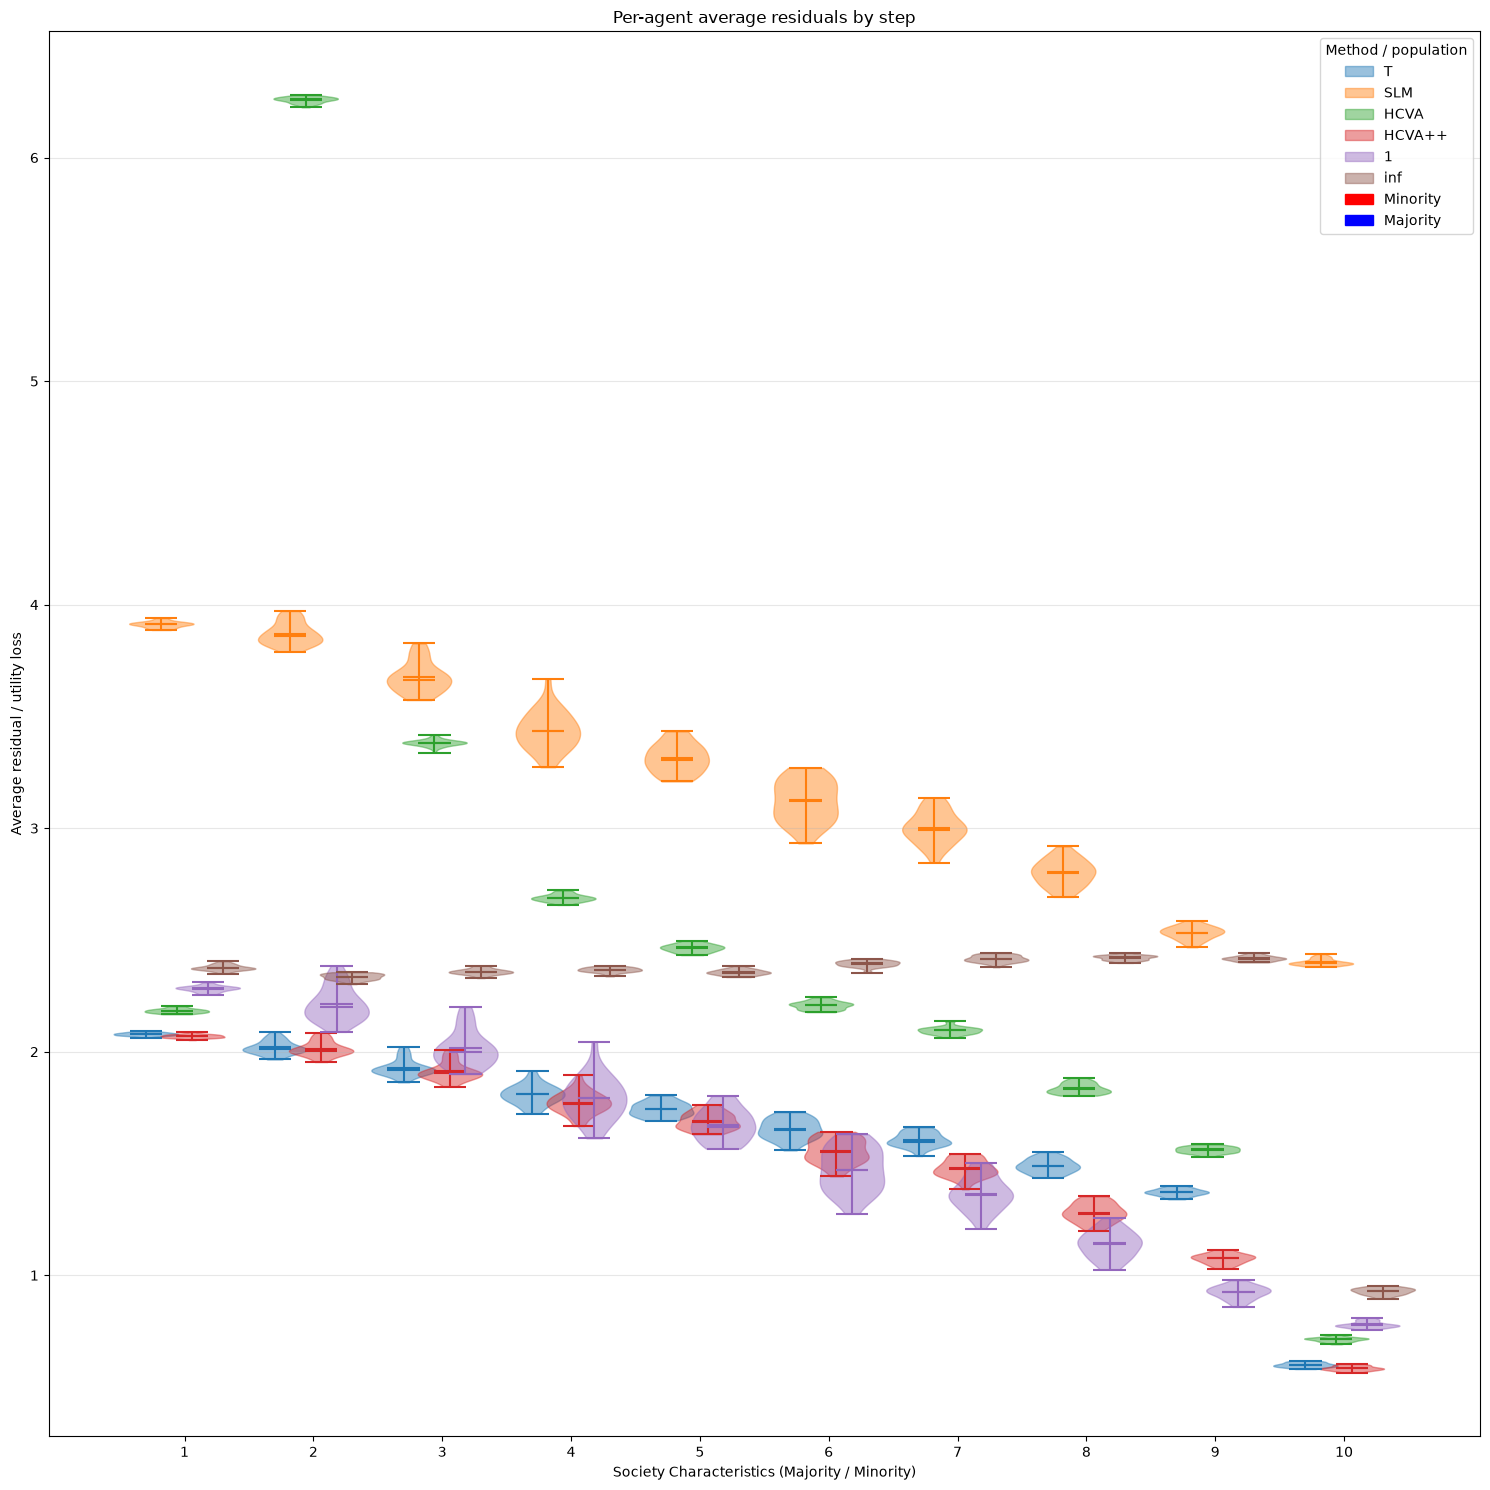

In [41]:
## load in prip_grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_grp_fact_oct/"
experiment_name = "vary_grp_fact_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_grp_fact/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_grp_fact/")
steps = 9 
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

### Averages vary_grp_fact comments:

- At step 9, everyone should be bottoming out, but are not all bottoming out.
- inf stays relatively high the whole time, so is probably bounded by the residual of the outlier. -> But I will need to check this in the data.
- HCVA old seems very sensitive
-  T and HCVA++ are similar.

So we can conclude that....

- SLM's method cannot handle this many collective PriPs? does the method break down mathematically?
- HCVA old is extreme, but may not be as representative. 50/50 should show HCVA(++) and T to be the same, and HCVA(++) should become more and more utilitarian (in comparison to T) as the majority increases. It is only HCVA++ that does this.
- T might be a good stand-in, but doesn't allow for disagreement between PriPs and PVS. HCVA++ does, as it is participatory.

,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,2035,2015,5.629152
1,T,1,2030,2020,5.631371
2,T,2,2009,2041,5.632554
3,T,3,2085,1965,5.639593
4,T,4,2013,2037,5.629692
...,...,...,...,...,...
175,inf,25,2002,2048,5.637799
176,inf,26,2084,1966,5.645924
177,inf,27,1990,2060,5.638469
178,inf,28,2022,2028,5.640143


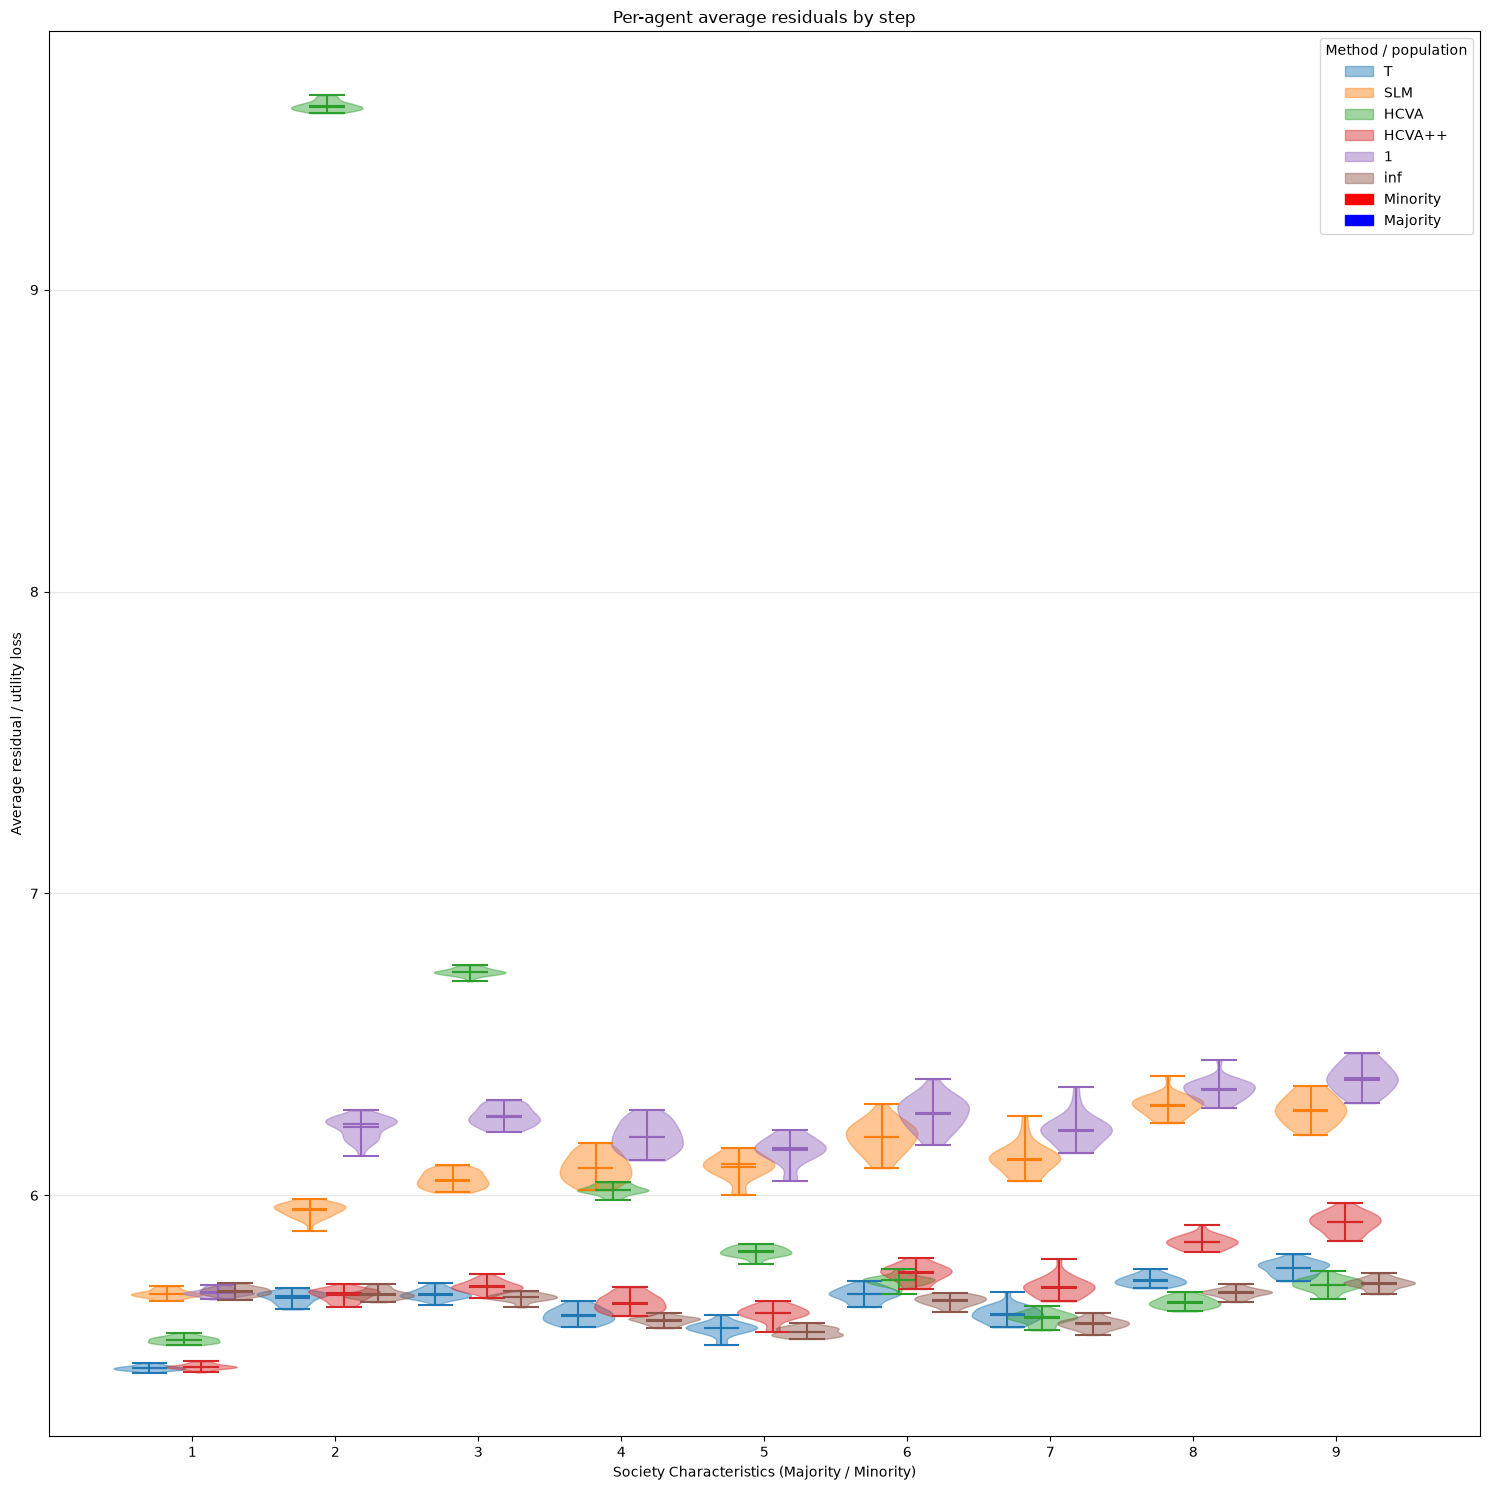

In [42]:
## The same type of plots, but for very prip_grp_fact

## load in grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_prip_grp_fact_oct/"
experiment_name = "vary_prip_grp_fact_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_prip_grp_fact/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_grp_fact/")
steps = 9 
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

## Thoughts on vary_prip_grp_fact
*scale: 0.11, 0.22, 0.33, 0.44, 0.55, 0.66, 0.77, 0.88, 1.0*

The prip_grp_fact is varying sizes of groups A and B for $PriP$ selection, having no $PVS-PriP$ alignment with agents' $PVS$.

so as the value increases, the size of group A increases, so it's again different ratios, but prips are completely separated from someones PVS. at the far ends the effect should be broadly the same.

- I don't think this should be used in the paper, it doesn't show much other than it makes little difference.

Varying the independent PriP group composition has a smaller effect on T, inf, and HCVA++ than on SLM, HCVA, and utilitarian aggregation. The experiment is asymmetric at the endpoints because a factor of 1 assigns every agent to the same PriP group.

,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,2502,1838,2.050036
1,T,1,2450,1890,2.047966
2,T,2,2523,1817,2.054640
3,T,3,2450,1890,2.050600
4,T,4,2474,1866,2.048195
...,...,...,...,...,...
175,inf,25,2426,1914,2.358014
176,inf,26,2475,1865,2.366217
177,inf,27,2448,1892,2.358425
178,inf,28,2501,1839,2.365318


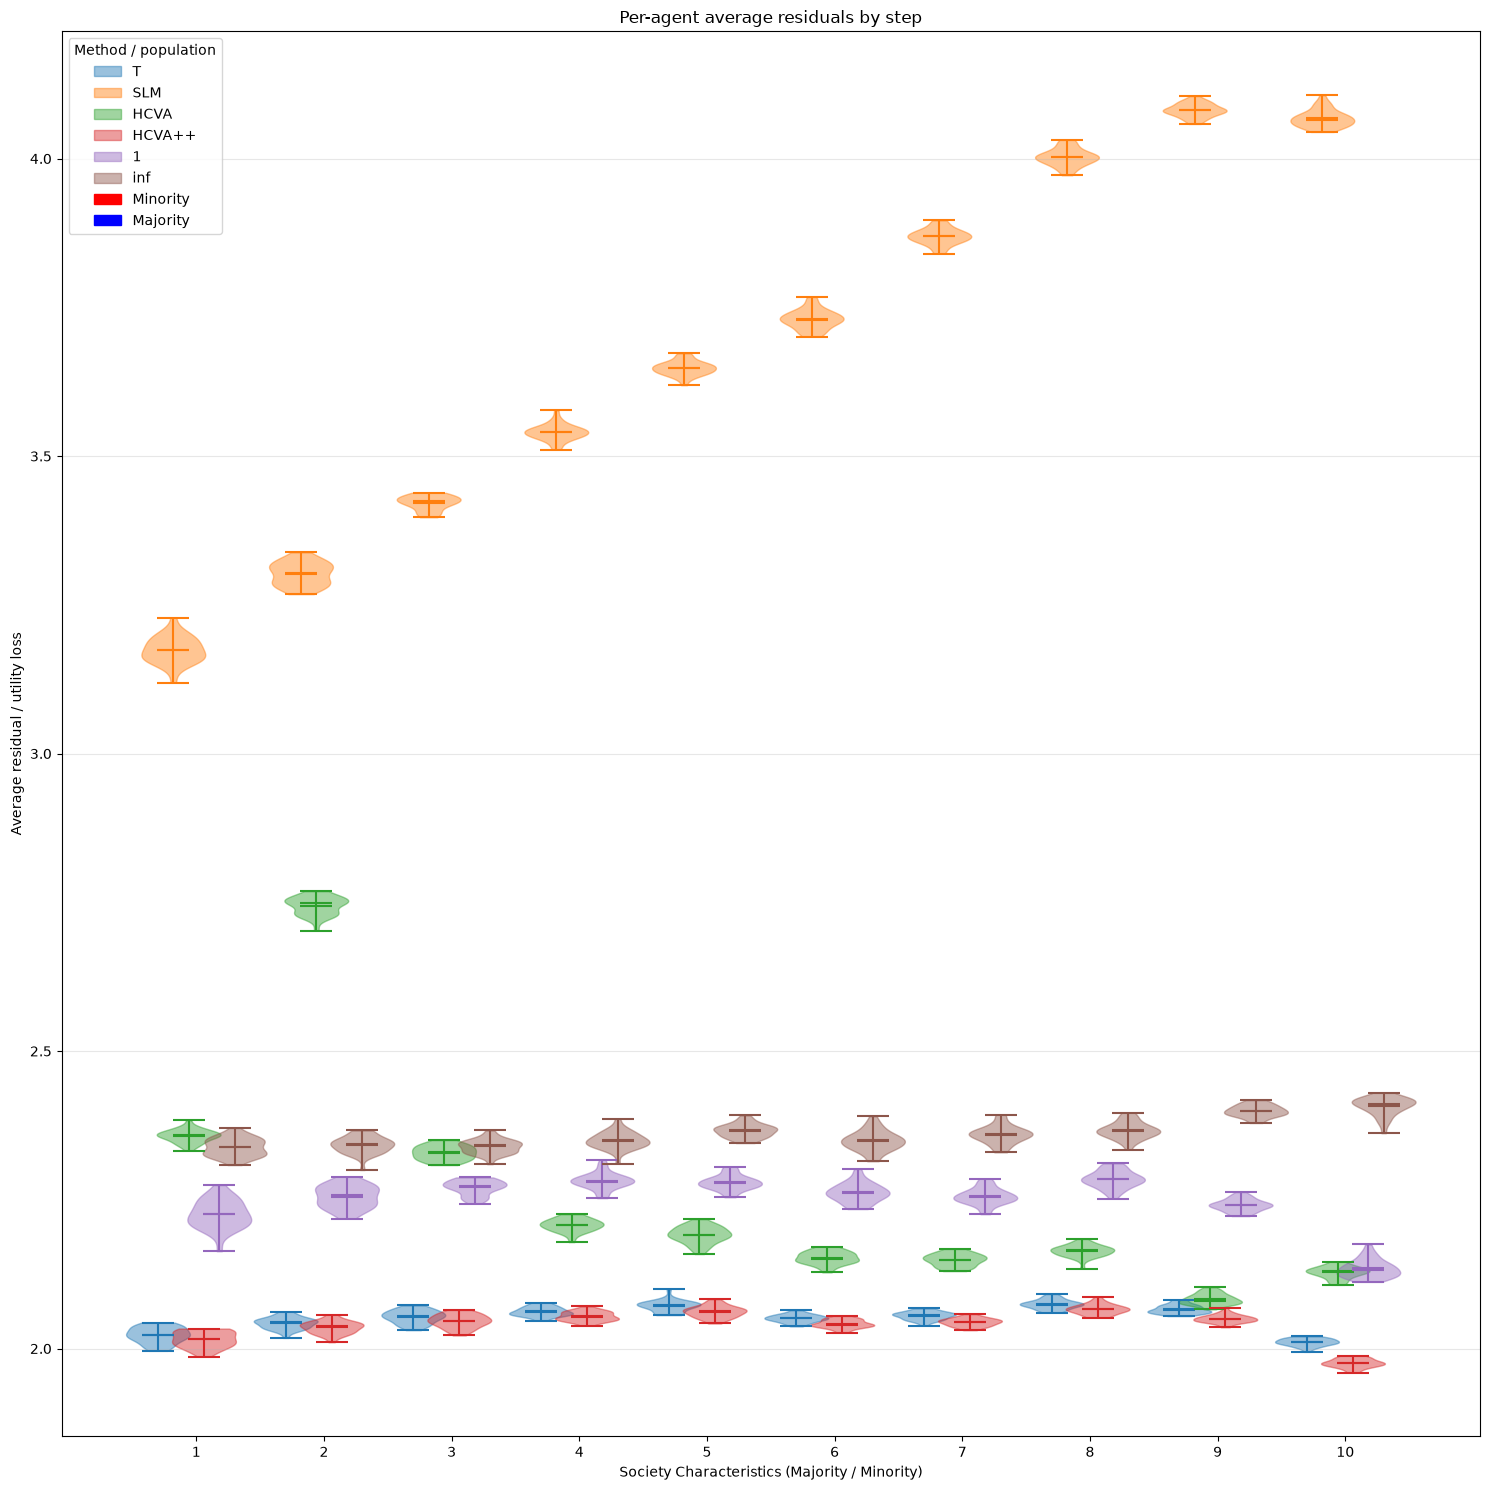

In [43]:
## The same type of plots, but for very prip_grp_fact

## load in grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_mup_vamu_oct/"
experiment_name = "vary_mup_vamu_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_mup_vamu/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_mup_vamu/")
steps = 9 
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

## Thoughts on vary_mup_vamu
*scale: 0.5, 0.55, 0.611, 0.66, 0.72, 0.77, 0.83*

As x increases, the mu (mean) of the p and va generation increases, this means the values should tend closer to the extremes.

- Expected results should be able to survive when groups are becoming more extreme, but SLM seems to fail.
- 1 and inf diverge as results become more extreme, this is because the outliers will become more extreme.
- T and HCVA++ are consistently stable and close together

,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,2256,1731,2.094609
1,T,1,2343,1644,2.097247
2,T,2,2295,1692,2.096129
3,T,3,2269,1718,2.094599
4,T,4,2255,1732,2.092631
...,...,...,...,...,...
175,inf,25,2222,1765,2.362059
176,inf,26,2294,1693,2.374625
177,inf,27,2327,1660,2.375995
178,inf,28,2274,1713,2.373411


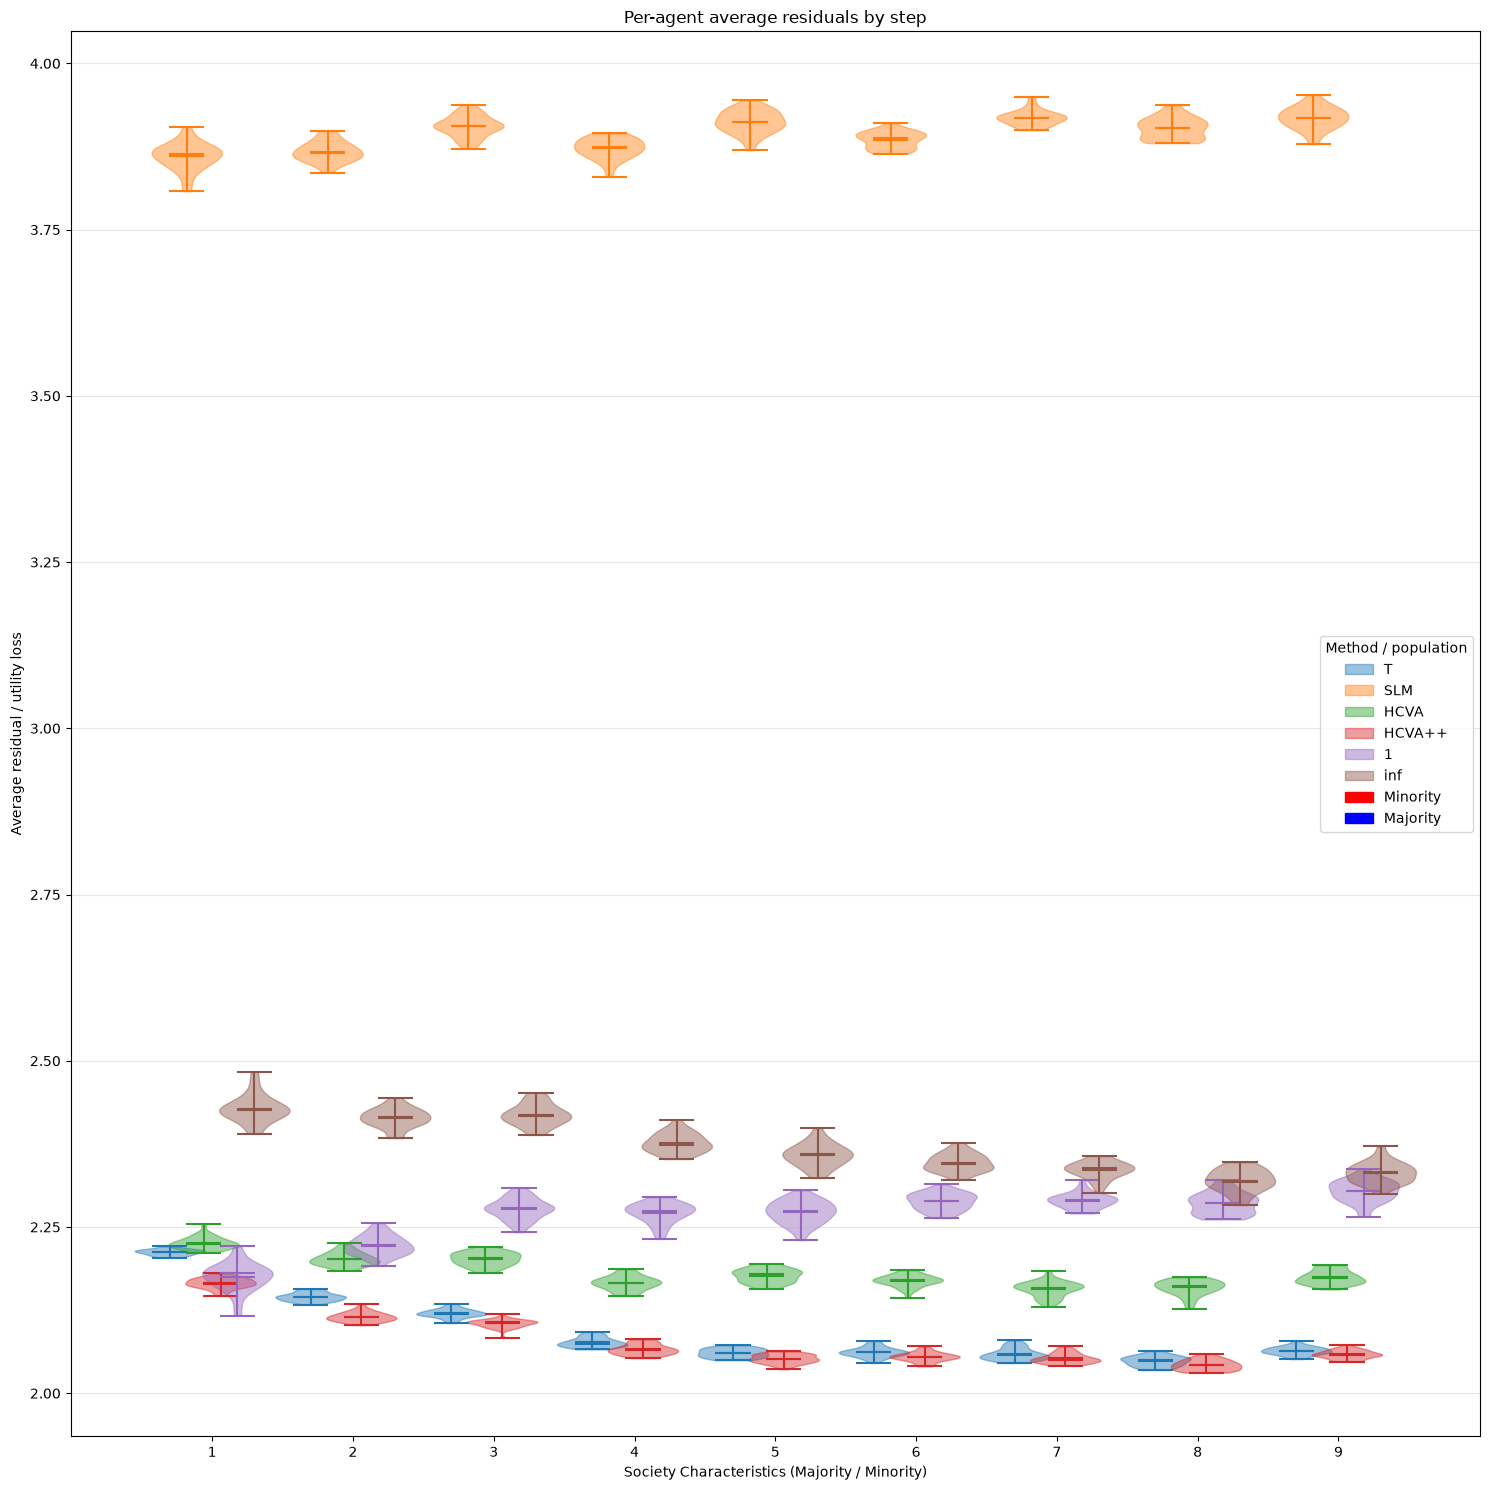

In [ ]:
## The same type of plots, but for very prip_grp_fact

## load in grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_sigma_prip_oct/"
experiment_name = "vary_sigma_prip_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_sigma_prip/")
steps = 8
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

## Thoughts on Sigma Prip
*scale 0.11, 0.22, 0.33, 0.44, 0.55, 0.66, 0.77, 0.88, 0.99. 1.0*

vary_sigma_prip describes how aligned an agents PriPs are with their PVS. as x increases, the PriPs become less aligned. It is expected that HCVA(++) and SLM will decrease in performance, as the data that informs their strategy becomes more *noisy*.

In reality, it seems that there is little to no changes, although the differences between 1 and inf decrease, and residuals overall decrease as alginment increases.

%%  The claim that residuals decrease as alignment increases should be checked carefully because the CSV averages aggregate over all parameter values; they do not directly prove a monotonic trend. - should this be proven by the individual data points?

,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,3035,1006,2.102683
1,T,1,3012,1029,2.101526
2,T,2,2992,1049,2.096531
3,T,3,2992,1049,2.095902
4,T,4,3001,1040,2.099116
...,...,...,...,...,...
175,inf,25,2997,1044,2.488327
176,inf,26,2963,1078,2.486136
177,inf,27,2995,1046,2.496368
178,inf,28,3003,1038,2.498748


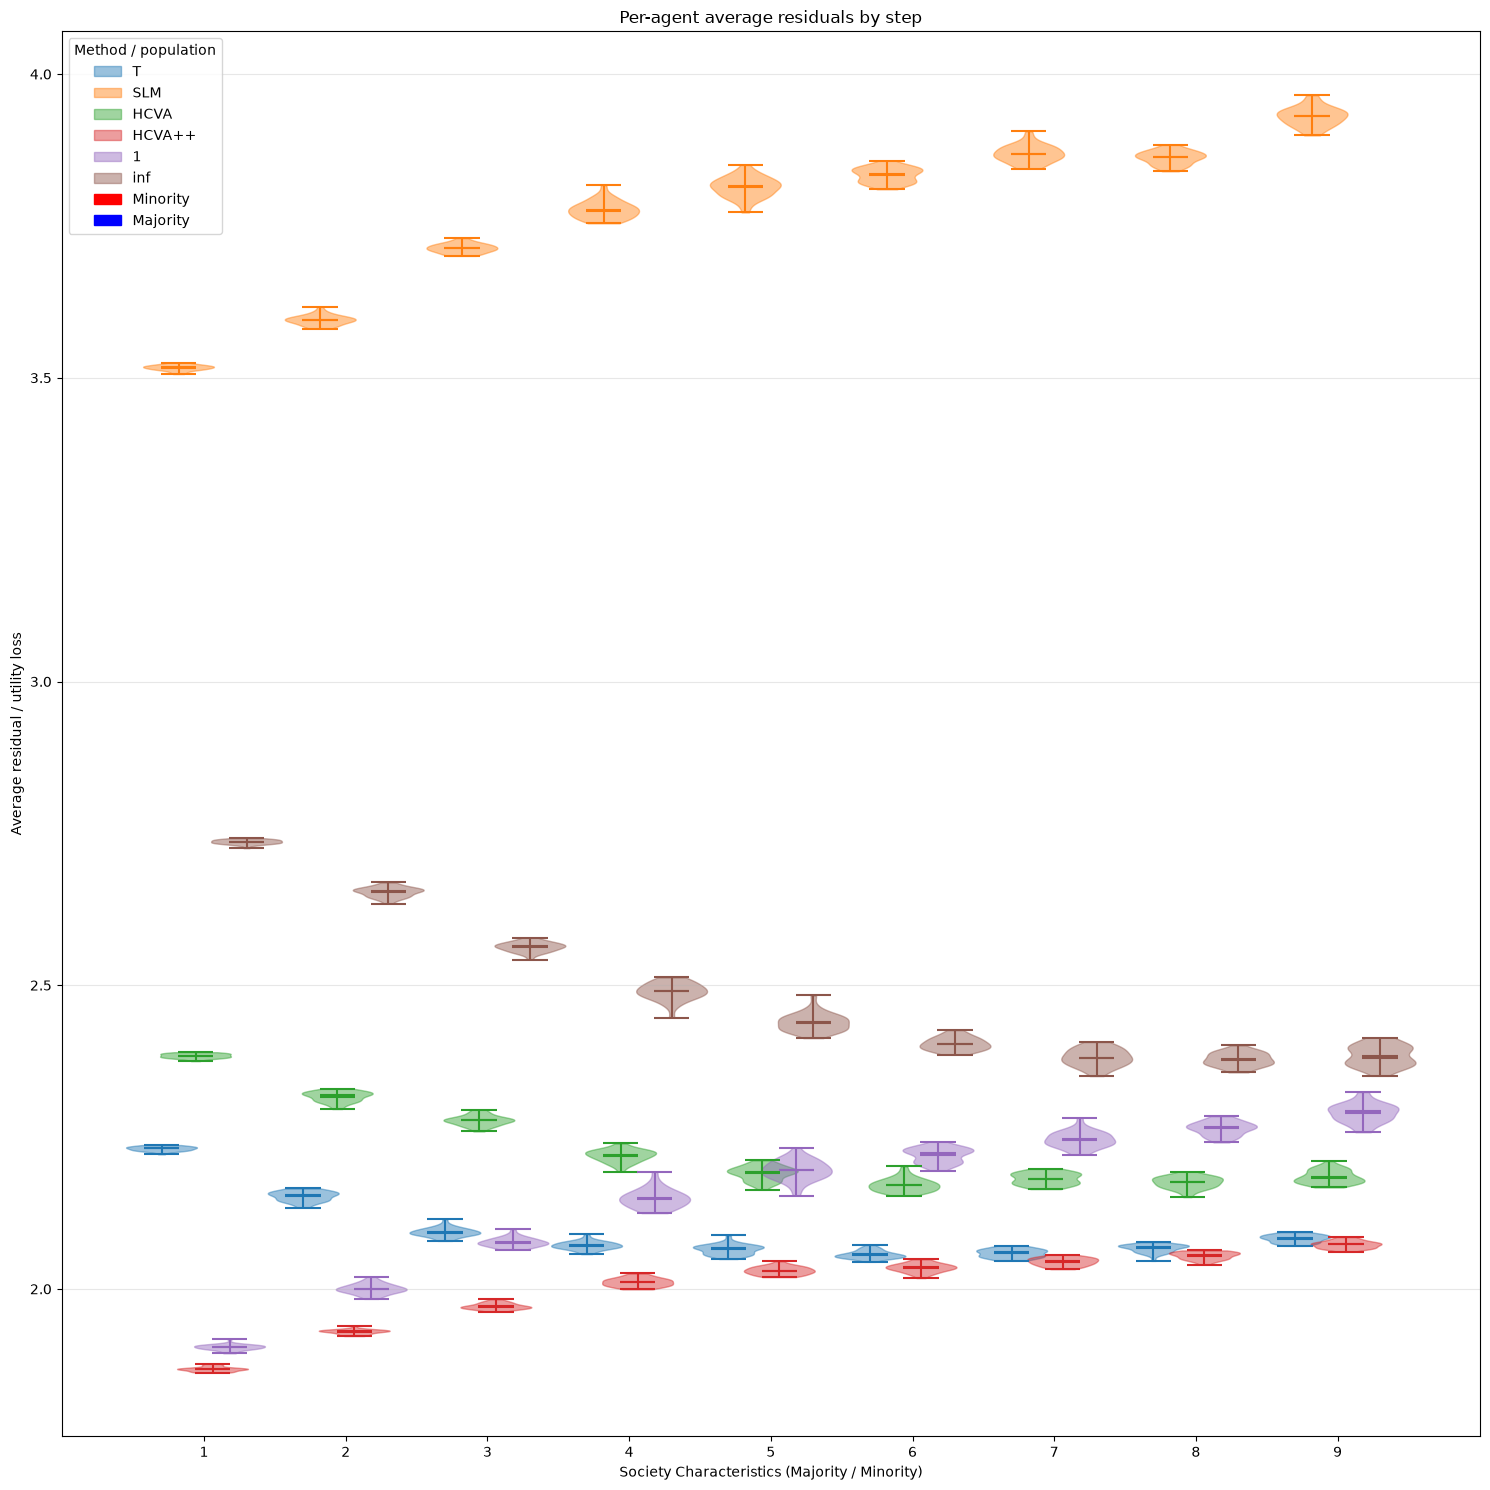

In [47]:
## The same type of plots, but for very prip_grp_fact

## load in grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/vary_sigma_prip_MINIMISE_oct/"
experiment_name = "vary_sigma_prip_MINIMISE_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip_MINIMISE/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/vary_sigma_prip_MINIMISE/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/vary_sigma_prip_MINIMISE/")
steps = 8
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

## Thoughts on Sigma PriP MINIMISE
*scale 0.11, 0.22, 0.33, 0.44, 0.55, 0.66, 0.77, 0.88, 0.99. 1.0*

Here, as the x axis increases, the agents are minimising their PriP strategy. Minimising means that agents always tend to give a prip of 0 (most utilitarian). as x increases the spread (sigma) becomes larger, so agents are generating more random PriP data.

This shows expectd results for HCVA++, when agents are maximising their preferences the residuals are the lowest, but as they begin to minimise, HCVA++ converges with T. As the minimisation happens, 1 and inf begin to converge too. this suggests that  

Under the minimising PriP strategy, increasing sigma introduces greater variation around utilitarian PriP values. HCVA++ loses some of its advantage and approaches T, while the residuals of 1 and inf become closer at higher sigma values.

,method,agent,majority_times,minority_times,average_utility_residual
0,T,0,239,260,3.836117
1,T,1,250,249,3.833470
2,T,2,219,280,3.814034
3,T,3,249,250,3.830747
4,T,4,252,247,3.841376
...,...,...,...,...,...
175,inf,25,257,242,4.173273
176,inf,26,257,242,4.167201
177,inf,27,258,241,4.177687
178,inf,28,251,248,4.139086


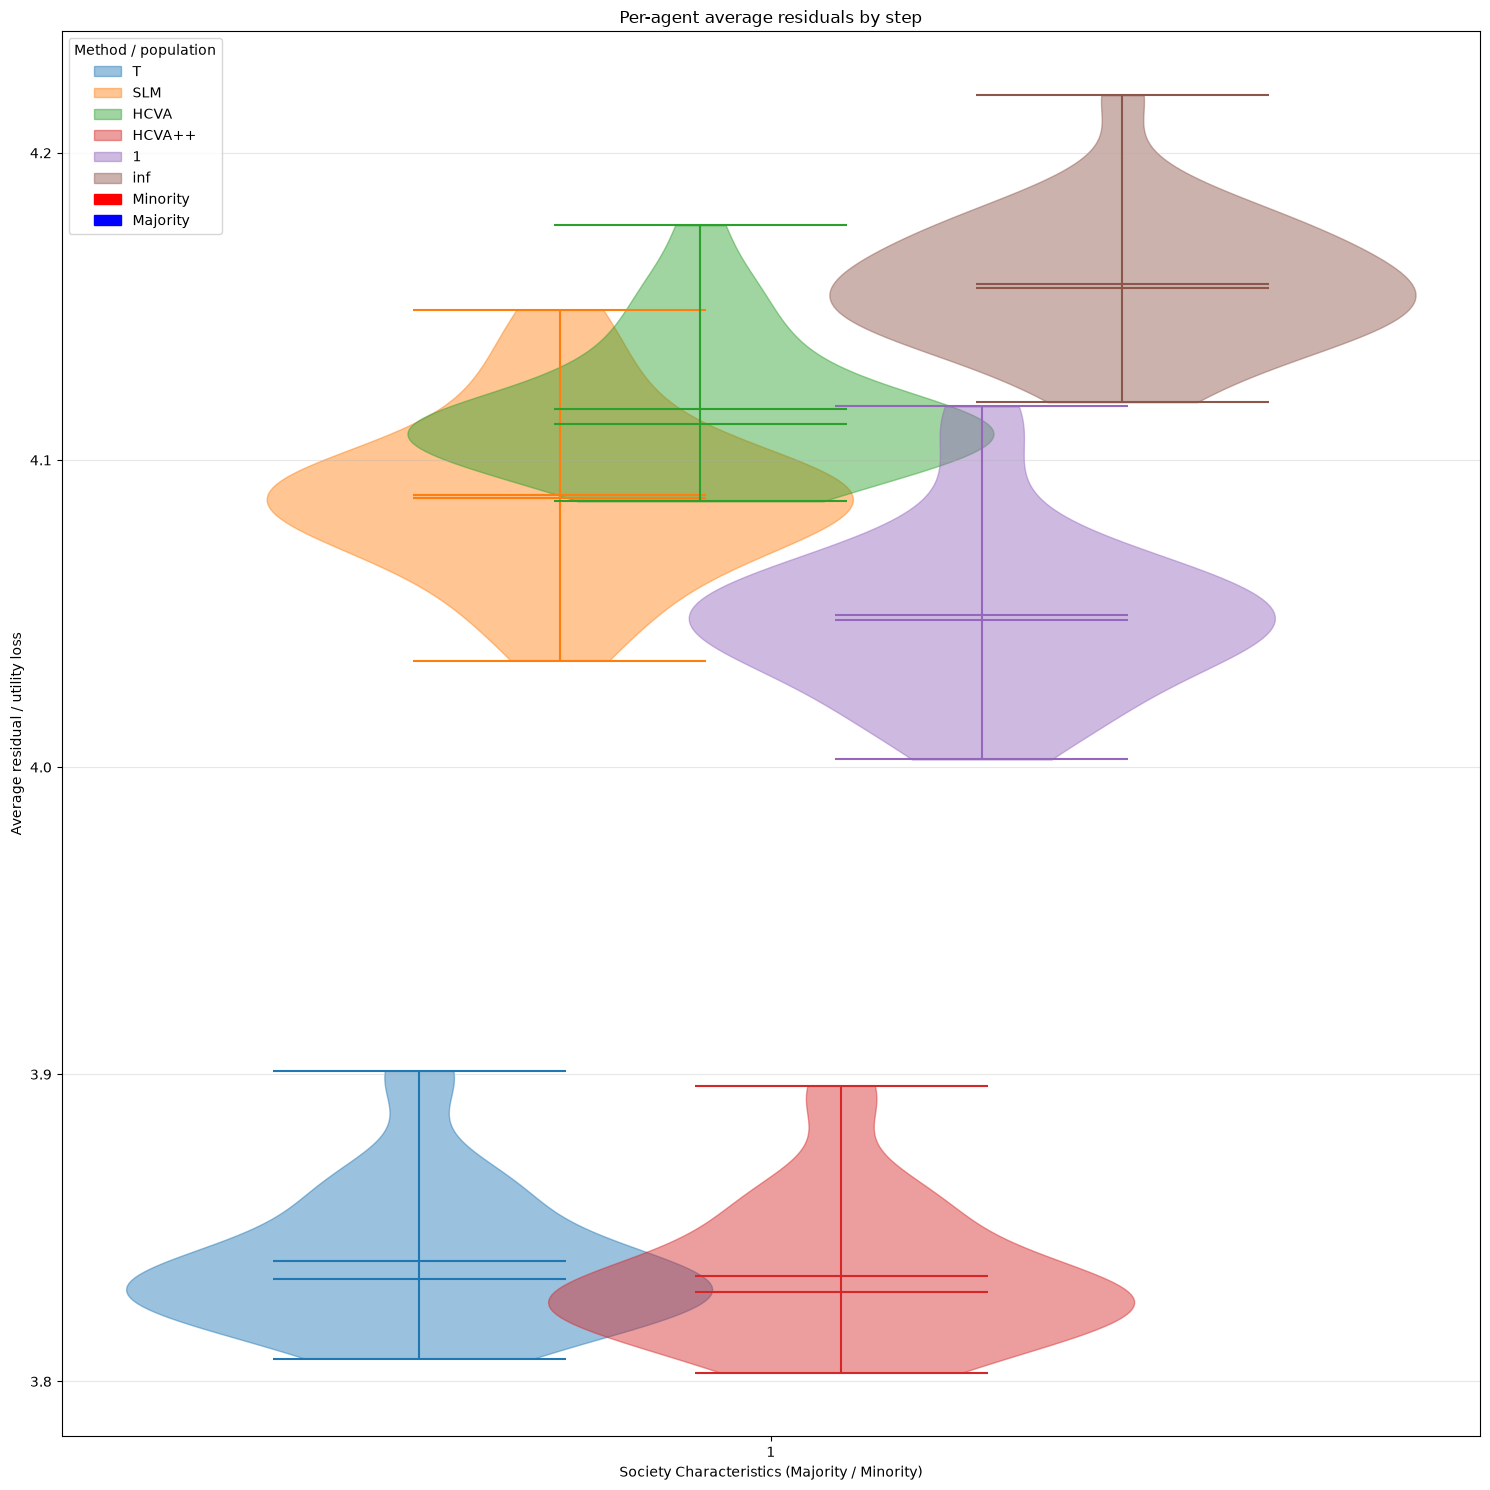

In [46]:
## The same type of plots, but for very prip_grp_fact

## load in grp_fact
CUR_DIR = str(pathlib.Path(os.path.abspath(os.curdir)).parent) # Note, this does not include a trailing '/'
output_dir = "plots/randoms_oct/"
experiment_name = "randoms_oct"

agents_pvs_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/randoms/PVS/")
agents_prip_dir = os.path.join(CUR_DIR, "value_systems/Synthetic/randoms/PriP/")
cons_dir = os.path.join(CUR_DIR, "results/randoms/")
steps = 0
dir_dict = plot_synth(agents_pvs_dir, agents_prip_dir,cons_dir, steps, experiment_name)

plot_averages(agents_pvs_dir, agents_prip_dir, dir_dict, output_dir)

## Thoughts on Randoms

- This reflects what we are seeing previously. T and HCVA++ consistently produce better residuals than the rest.

With random PVS and PriP data, HCVA++ and T have the lowest mean residuals and are effectively tied. This suggests robustness, but statistical uncertainty or repeated-seed analysis is needed before claiming a reliable performance advantage.

## Thoughts on what to do next

- Make sure there is also some representation of the gini index so we can say we look at residuals and a fairness (second) metric

- 


Why is everything so similar?
- Is it that the soicety structure is just too similar


Heatmap - NOTE: Leave this for now.
- can we do a heatmap? 5x5 or 10x10
    - Are we changing ethical principles, values, see the heatmap NOT FOR NOW 

TODO:
- Do a swarm plot over the violins

- Do a plot to see if societies are significantly different, by plotting the p=1 p=inf differences. like before

- are the distributions the same but people have moved the same.

- Do the abstracted version rather than individual datapoints
    - Look at each agent -> see if each agent over 500 experiments (Where I am maj/min x/y number of times), and my total satisfaction was blah
        - over each agent, i was minority 200 times, majority 300 times, What was my overall score.